# 02 — Player-gameweek panel: sanity checks

Reviews `data/player_gw_panel.csv` built by `src/build_dataset.py`.

Each player is treated as an asset and each gameweek as a period; `total_points` is the period return.
Every trailing feature uses only earlier gameweeks, so this table can be backtested honestly.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

panel = pd.read_csv("../data/player_gw_panel.csv")
played = panel[panel["total_points"].notna()]
upcoming = panel[panel["total_points"].isna()]
print(panel.shape, "| played rows:", len(played), "| upcoming rows:", len(upcoming))
print("gameweeks:", sorted(panel["round"].unique()))

(5219, 37) | played rows: 4551 | upcoming rows: 668
gameweeks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


## 1. Spot-check one player

Compare these against the player's history on the FPL website. In row *n*, `pts_mean_3` should be the mean of the previous three rows' `total_points`, never including row *n* itself.

In [2]:
cols = ["round", "price_m", "difficulty", "minutes", "total_points",
        "pts_mean_3", "pts_mean_5", "pts_std_5", "play_rate_5", "xgi_per90_5"]
panel.loc[panel["web_name"] == "Haaland", cols]

,round,price_m,difficulty,minutes,total_points,pts_mean_3,pts_mean_5,pts_std_5,play_rate_5,xgi_per90_5
3280,1,15.5,3.0,90.0,2.0,NaN,NaN,NaN,NaN,NaN
3281,2,15.5,3.0,90.0,13.0,2.000000,2.00,NaN,1.0,0.760000
3282,3,15.5,2.0,90.0,9.0,7.500000,7.50,NaN,1.0,0.710000
3283,4,15.5,4.0,90.0,9.0,8.000000,8.00,5.567764,1.0,0.986667
3284,5,15.6,3.0,90.0,6.0,10.333333,8.25,4.573474,1.0,0.960000
3285,6,15.6,4.0,79.0,6.0,8.000000,7.80,4.086563,1.0,0.990000
3286,7,15.7,2.0,90.0,13.0,7.000000,8.60,2.880972,1.0,0.943052
3287,8,15.7,3.0,NaN,NaN,8.333333,8.60,2.880972,1.0,1.033257


## 2. Do the features carry any signal? (information coefficient)

The **information coefficient (IC)** is the rank correlation between a signal known before the deadline and the return that followed, calculated per gameweek.
In equity factor research an IC around 0.05–0.10 is already useful. Only a few gameweeks exist yet, so treat these values as noisy.

In [3]:
signals = ["pts_mean_3", "pts_mean_5", "pts_sharpe_5", "mins_mean_3",
           "start_rate_5", "xgi_per90_5", "price_m", "difficulty"]

def rank_ic(df, signal):
    d = df[[signal, "total_points"]].dropna()
    return d[signal].rank().corr(d["total_points"].rank()) if len(d) > 20 else float("nan")

ic = pd.DataFrame({
    s: played[played["round"] >= 3].groupby("round").apply(rank_ic, signal=s)
    for s in signals
})
ic.loc["mean"] = ic.mean()
ic.round(3)

,pts_mean_3,pts_mean_5,pts_sharpe_5,mins_mean_3,start_rate_5,xgi_per90_5,price_m,difficulty
round,,,,,,,,
3,0.710,0.710,NaN,0.762,0.703,0.153,0.302,-0.028
4,0.671,0.671,0.449,0.676,0.623,0.150,0.368,-0.039
5,0.710,0.691,0.498,0.717,0.648,0.159,0.353,-0.003
6,0.674,0.656,0.441,0.681,0.619,0.186,0.345,-0.037
7,0.631,0.655,0.481,0.678,0.649,0.067,0.337,-0.053
mean,0.679,0.677,0.467,0.703,0.649,0.143,0.341,-0.032


The **minutes / start-rate** signals rank highest: a player who doesn't play can't score.
That is why rotation risk sits at the base of the model. In the README this is the Layer 2 survival model.

These ICs are **inflated**, though. Hundreds of squad players almost never play, and anyone can predict their 0 points.
The more honest test asks which signals still separate players **among regular starters**. That is the decision you actually face when choosing between players who will play.

In [4]:
starters = played[(played["round"] >= 3) & (played["start_rate_5"] >= 0.8)]
ic_starters = pd.DataFrame({
    s: starters.groupby("round").apply(rank_ic, signal=s) for s in signals
})
ic_starters.loc["mean"] = ic_starters.mean()
ic_starters.round(3)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,pts_mean_3,pts_mean_5,pts_sharpe_5,mins_mean_3,start_rate_5,xgi_per90_5,price_m,difficulty
round,,,,,,,,
3,0.037,0.037,NaN,0.145,NaN,0.056,0.089,-0.234
4,0.297,0.297,0.246,0.128,NaN,0.149,0.279,-0.102
5,0.124,0.118,0.127,0.233,NaN,-0.027,0.131,-0.111
6,0.210,0.184,0.251,0.154,0.171,0.183,0.168,-0.028
7,0.055,0.062,0.159,0.130,0.201,0.027,0.062,-0.257
mean,0.145,0.140,0.196,0.158,0.186,0.078,0.146,-0.146


## 3. Risk-return map for the next gameweek

Trailing mean points (expected return) against trailing volatility (risk), for regular starters. The dashed line is the 2-point appearance return, FPL's risk-free rate.
Players toward the upper-left give more return per unit of risk, the same reading as a Markowitz efficient frontier.

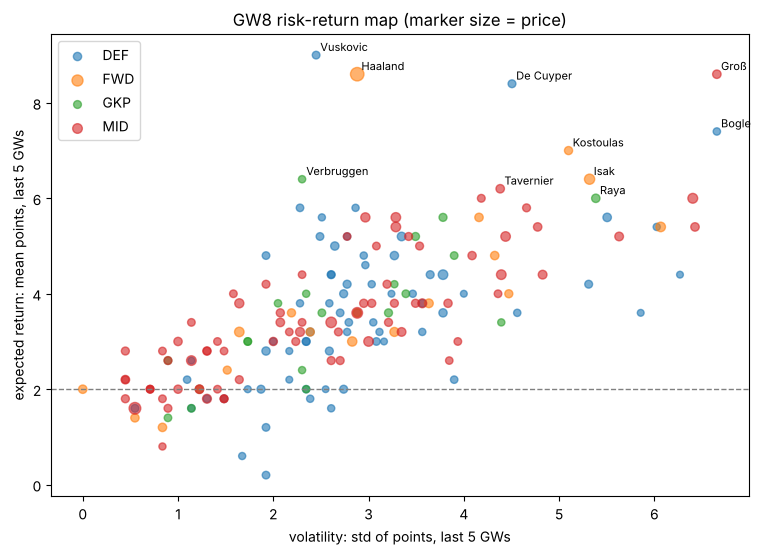

In [5]:
nxt = upcoming[(upcoming["gws_observed"] >= 5) & (upcoming["start_rate_5"] >= 0.8)]
fig, ax = plt.subplots(figsize=(9, 6))
for pos, grp in nxt.groupby("position"):
    ax.scatter(grp["pts_std_5"], grp["pts_mean_5"], label=pos, alpha=0.6, s=grp["price_m"] * 6)
for _, r in nxt.nlargest(10, "pts_mean_5").iterrows():
    ax.annotate(r["web_name"], (r["pts_std_5"], r["pts_mean_5"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(2, ls="--", c="grey", lw=1)
ax.set_xlabel("volatility: std of points, last 5 GWs")
ax.set_ylabel("expected return: mean points, last 5 GWs")
ax.set_title(f"GW{int(upcoming['round'].iloc[0])} risk-return map (marker size = price)")
ax.legend()
plt.show()

In [6]:
nxt.sort_values("pts_sharpe_5", ascending=False)[
    ["web_name", "position", "price_m", "pts_mean_5", "pts_std_5", "pts_sharpe_5", "pts_per_m_5", "difficulty"]
].head(15)

,web_name,position,price_m,pts_mean_5,pts_std_5,pts_sharpe_5,pts_per_m_5,difficulty
4031,Vuskovic,DEF,5.1,9.0,2.449490,2.857738,1.764706,4.0
3287,Haaland,FWD,15.7,8.6,2.880972,2.290893,0.547771,3.0
871,Verbruggen,GKP,4.6,6.4,2.302173,1.911238,1.391304,4.0
2111,Bobb,MID,5.5,2.8,0.447214,1.788854,0.509091,2.0
895,Van Hecke,DEF,4.9,5.8,2.280351,1.666410,1.183673,4.0
2671,Muharemović,DEF,5.0,4.8,1.923538,1.455651,0.960000,3.0
903,F.Kadıoğlu,DEF,4.4,5.6,2.509980,1.434274,1.272727,4.0
919,De Cuyper,DEF,5.3,8.4,4.505552,1.420470,1.584906,4.0
911,Boscagli,DEF,4.5,5.8,2.863564,1.327018,1.288889,4.0
2895,Jacquet,DEF,5.1,5.2,2.489980,1.285151,1.019608,3.0


## 4. Rotation risk at a glance

Share of the last five gameweeks in which each player got any minutes. A few players are nailed starters, many never play, and the in-between group is where the minutes model earns its value.

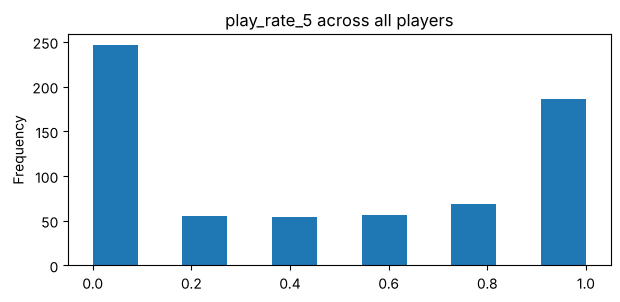

In [7]:
upcoming["play_rate_5"].plot.hist(bins=11, figsize=(7, 3), title="play_rate_5 across all players")
plt.show()

## Caveats

- Only a handful of gameweeks so far. Five-game volatility and IC are very noisy, and past seasons' data will make both more stable.
- Trailing means are a **naive** expected-points estimate. The next step is a baseline model that has to beat them.
- Players who joined mid-season have short histories (`gws_observed`).